In [36]:
# Import required libraries
import matplotlib.pyplot as plt                           # for plotting
from sklearn.datasets import load_breast_cancer           # breast cancer dataset from scikit-learn
from sklearn.model_selection import train_test_split      # to split dataset into training and testing sets
from sklearn.preprocessing import StandardScaler          # tool for feature scaling
from keras.models import Sequential                       # Sequential model from keras to build feedforward neural networks
from keras.layers import Dense, Input
from keras.utils import to_categorical                    # for one-hot encoding of labels

In [37]:
# Loading data
breast_cancer = load_breast_cancer()
x = breast_cancer.data
y = breast_cancer.target

# Print feature names for context
print('Feature names: ', breast_cancer.feature_names)
print('Target names: ', breast_cancer.target_names)

# Print the first 2 samples with their labels
print(f"Features = {x[0]}, Label = {y[0]} ({breast_cancer.target_names[y[0]]})")
print(f"Features = {x[20]}, Label = {y[20]} ({breast_cancer.target_names[y[20]]})")

Feature names:  ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Target names:  ['malignant' 'benign']
Features = [1.799e+01 1.038e+01 1.228e+02 1.001e+03 1.184e-01 2.776e-01 3.001e-01
 1.471e-01 2.419e-01 7.871e-02 1.095e+00 9.053e-01 8.589e+00 1.534e+02
 6.399e-03 4.904e-02 5.373e-02 1.587e-02 3.003e-02 6.193e-03 2.538e+01
 1.733e+01 1.846e+02 2.019e+03 1.622e-01 6.656e-01 7.119e-01 2.654e-01
 4.601e-01 1.189e-01], Label = 0 (malignant)
Features = [1.308e+01 1.571e+01 8.563e+01 5.200e+02

In [38]:
# One-hot encoding of labels
y_encoded = to_categorical(y)

In [39]:
# Splitting data into training and test
x_train, x_test, y_train, y_test = train_test_split(x, y_encoded, test_size=0.2, random_state=42)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(455, 30) (114, 30) (455, 2) (114, 2)


In [40]:
# Feature scaling for standardization
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [41]:
# Building the model
model = Sequential()
model.add(Input(shape=(30,)))
model.add(Dense(16, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(2, activation='softmax'))
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 650 (2.54 KB)

 Trainable params: 650 (2.54 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
training_values = model.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.8297 - loss: 0.5303 - val_accuracy: 0.8791 - val_loss: 0.4510
Epoch 2/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9066 - loss: 0.4193 - val_accuracy: 0.9121 - val_loss: 0.3523
Epoch 3/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9258 - loss: 0.3381 - val_accuracy: 0.9231 - val_loss: 0.2817
Epoch 4/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9313 - loss: 0.2761 - val_accuracy: 0.9341 - val_loss: 0.2343
Epoch 5/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9368 - loss: 0.2311 - val_accuracy: 0.9451 - val_loss: 0.2014
Epoch 6/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9451 - loss: 0.1972 - val_accuracy: 0.9451 - val_loss: 0.1796
Epoch 7/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9505 - loss: 0.1718 - val_accuracy: 0.9451 - val_loss: 0.1639
Epoch 8/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9533 - loss: 0.1523 - val_accuracy: 0.9451 - val_l

In [43]:
# Evaluate the model
loss, accuracy = model.evaluate(x_test, y_test)

# Print the test accuracy as a percentage
print(f'Accuracy: {accuracy*100:.2f}%')

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9737 - loss: 0.1043
Accuracy: 97.37%


[0.530333399772644, 0.4193314015865326, 0.33806759119033813, 0.27612969279289246, 0.23107023537158966, 0.19720357656478882, 0.17182086408138275, 0.1522597074508667, 0.13654562830924988, 0.12306852638721466]
[0.4509831964969635, 0.3523150384426117, 0.2817409336566925, 0.23430554568767548, 0.20136210322380066, 0.17963430285453796, 0.1639399230480194, 0.15175524353981018, 0.14146165549755096, 0.13353008031845093]


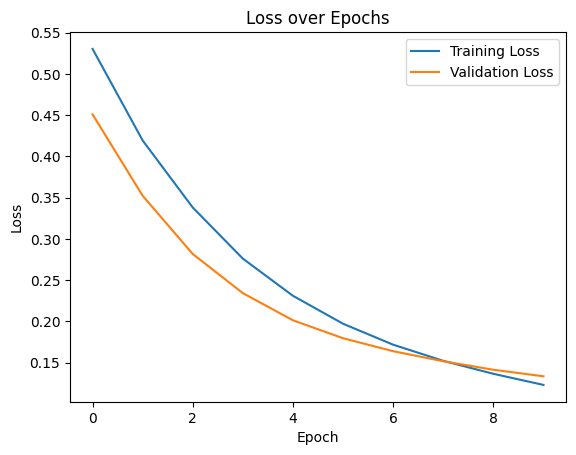



[0.8296703100204468, 0.906593382358551, 0.9258241653442383, 0.9313187003135681, 0.9368131756782532, 0.9450549483299255, 0.9505494236946106, 0.9532967209815979, 0.9532967209815979, 0.9642857313156128]
[0.8791208863258362, 0.9120879173278809, 0.9230769276618958, 0.9340659379959106, 0.9450549483299255, 0.9450549483299255, 0.9450549483299255, 0.9450549483299255, 0.9560439586639404, 0.9780219793319702]


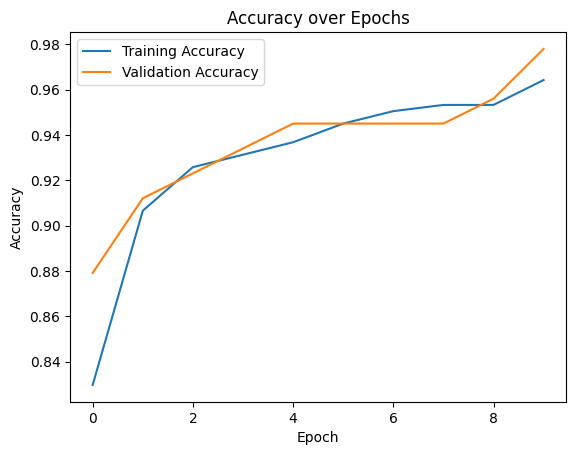

In [44]:
# History for loss
print(training_values.history['loss'])
print(training_values.history['val_loss'])

# START CODE HERE
history = training_values.history
plt.plot(history['loss'], label='Training Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# END CODE HERE

plt.show()
print('\n')

# History for accuracy
print(training_values.history['accuracy'])
print(training_values.history['val_accuracy'])

# START CODE HERE
plt.plot(history['accuracy'], label='Training Accuracy')
plt.plot(history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
# END CODE HERE

plt.show()


Before scaling the data, the accuracy was at 78% and the values seemed to drop steeply and then rise again, resulting in a very erratic plot. After scaling the data, the accuracy reached 95.61% with a loss of 0.1905, which means 96 out of every 100 samples are correctly classified as malignant or benign.